Uploaded the zip file(database of gears) into collab. Now analyzing the contents of the zip to understand the data should be a solid first step

In [ ]:
from zipfile import ZipFile
from pathlib import Path

# Locate the ZIP file
zip_path = Path("/content/gearboxdata.zip")

# Inspect its contents
with ZipFile(zip_path, "r") as zip_file:
    filenames = zip_file.namelist()

    print("Total files:", len(filenames))

Total files: 22


This tells us we have 22 files only. Since this is a small amoust lets print out the names

In [ ]:
for filename in filenames[:22]:
    print(filename)

Healthy Data/
Healthy Data/h30hz0.txt
Healthy Data/h30hz10.txt
Healthy Data/h30hz20.txt
Healthy Data/h30hz30.txt
Healthy Data/h30hz40.txt
Healthy Data/h30hz50.txt
Healthy Data/h30hz60.txt
Healthy Data/h30hz70.txt
Healthy Data/h30hz80.txt
Healthy Data/h30hz90.txt
BrokenTooth Data/
BrokenTooth Data/b30hz0.txt
BrokenTooth Data/b30hz10.txt
BrokenTooth Data/b30hz20.txt
BrokenTooth Data/b30hz30.txt
BrokenTooth Data/b30hz40.txt
BrokenTooth Data/b30hz50.txt
BrokenTooth Data/b30hz60.txt
BrokenTooth Data/b30hz70.txt
BrokenTooth Data/b30hz80.txt
BrokenTooth Data/b30hz90.txt


Looking at the file names, a few noticable patterns emerge. The files appear to be divided into two categories: healthy data and broken-tooth data(unhealthy gear systems). Within each category, the file names seem to follow a consistent numerical naming convention, with the tailing numbers possibly representing a variance of some kind(h30hz10 or h30hz90). Hz refers to frequency, so I think the number of catagorically increasing "healthy" or "broken" files will help the model build some nuance when dealing with either type of gear situation.



To better understand what kind of data we are working with so we can better teach the model, lets open `Healthy Data/h30hz0.txt` and take a look at what infomation we will be dealing with.

In [ ]:
# Open the ZIP file
with ZipFile(zip_path, "r") as zip_file:

    # Read one healthy gearbox recording
    data = zip_file.read(
        "Healthy Data/h30hz0.txt"
    ).decode("utf-8", errors="replace")

# Separate the contents into lines
lines = data.splitlines()

print("Number of lines:", len(lines))
print("\nFirst 5 lines:")

for line in lines[:5]:
    print(repr(line))

Number of lines: 88834

First 5 lines:
''
'4.63671e+000\t5.16978e-001\t-3.20594e+000\t1.82241e+000\t'
'1.99280e+000\t4.18466e+000\t-2.74061e+000\t2.80436e+000\t'
'-3.76411e+000\t9.97335e-001\t-1.30309e+000\t1.83668e+000\t'
'-4.55871e+000\t6.10433e+000\t-1.72069e+000\t1.72311e+000\t'


Honestly, the first 5 lines doesn't help create any sense. Some noticable patterns stand out, like the first column decreasing. But it would be little information to judge based off currently.

Some things I can inference/tell from the output are:


*   88,834 lines were detected, but the first line is empty.

*   Each measurement appears to contain four numerical values, separated by tabs (\t).

*   Each file represents a recording, so we need to preserve which recording each measurement came from.





So my next step should also include some sort of data visualization, like a graph. But first, before I begin currating my dataset, I want to try to compare the healthy gear systems to the unhealthy ones, so I will try to open `BrokenTooth Data/b30hz0.txt`

In [ ]:
import pandas as pd
from io import StringIO
from zipfile import ZipFile

# Going to create a function to expediate the process of load 22 recordings each

def load_recording(zip_file, filename):
    # Read the file from the ZIP
    text = zip_file.read(filename).decode("utf-8")

    # Convert the text into a table
    df = pd.read_csv(
        StringIO(text),
        sep="\t",
        header=None
    )

    # Remove completely empty rows and columns
    df = df.dropna(axis=0, how="all")
    df = df.dropna(axis=1, how="all")

    # Convert the measurements to numbers
    df = df.apply(pd.to_numeric, errors="coerce")

    # Remove rows containing missing values
    df = df.dropna()

    return df


with ZipFile(zip_path, "r") as zip_file:
    healthy_data = load_recording(
        zip_file, "Healthy Data/h30hz0.txt"
    )

    faulty_data = load_recording(
        zip_file, "BrokenTooth Data/b30hz0.txt"
    )

print("Healthy shape:", healthy_data.shape)
print("Faulty shape:", faulty_data.shape)

Healthy shape: (88832, 4)
Faulty shape: (88320, 4)


With the data now accessible, visualization is the next step. To do this I used AI to help with plot the data because I am not great with the matplotlib library, and my understanding of it is very rudimentary - newbie if you will.

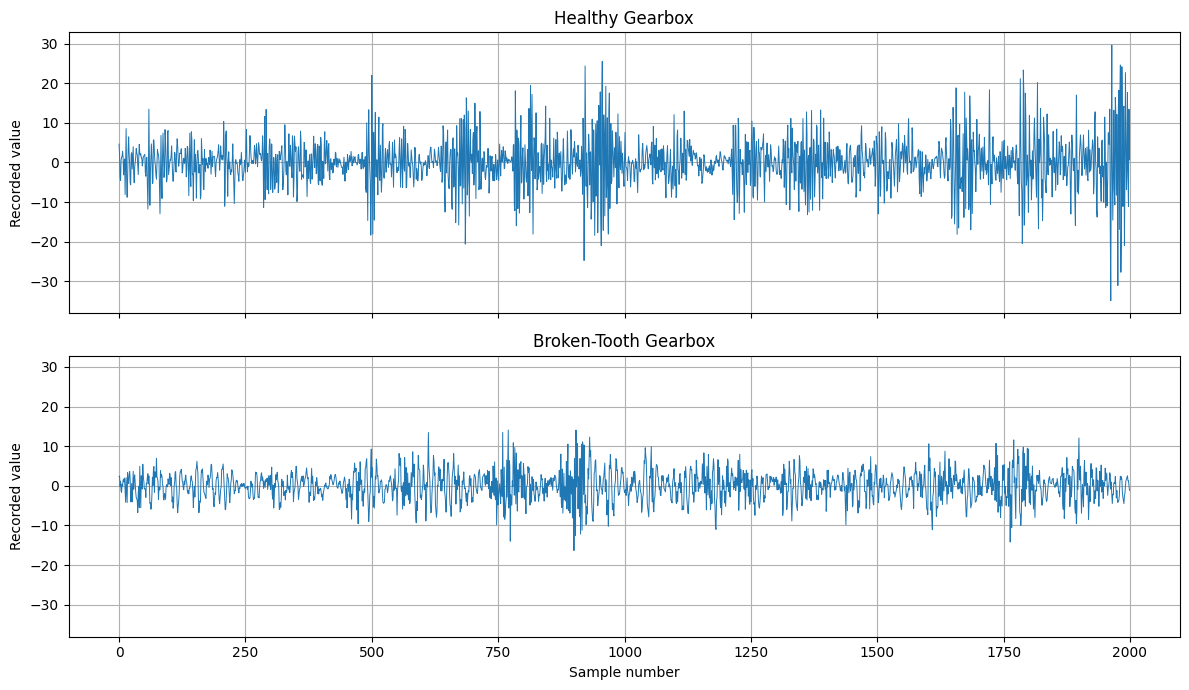

In [ ]:
import matplotlib.pyplot as plt

# Number of measurements to display
num_samples = 2000

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True,
    sharey=True
)

# Plot the first column of the healthy recording
axes[0].plot(
    healthy_data.iloc[:num_samples, 0],
    linewidth=0.7
)
axes[0].set_title("Healthy Gearbox")
axes[0].set_ylabel("Recorded value")
axes[0].grid(True)

# Plot the first column of the faulty recording
axes[1].plot(
    faulty_data.iloc[:num_samples, 0],
    linewidth=0.7
)
axes[1].set_title("Broken-Tooth Gearbox")
axes[1].set_xlabel("Sample number")
axes[1].set_ylabel("Recorded value")
axes[1].grid(True)

plt.tight_layout()
plt.show()

Using the 1st column of both healthy and unhealthy gear system recording, we can visual a graph using the recorded measures of the first sensor.

An aparrent difference in both the visualized records stands out - the healthhly gearbox has a more jittery graph. It also seems more condensed.

Although we have a graph, it only displayed the first 2,000 measurements from Sensor 1. We have four sensors and tens of thousands of measurements. We should try to investigate all of them using statistics.


_______________________________________________________________________________


Some of the statistics that seem approiate at first to use are mean, standard dev, max and min, range. However - acknowledging that my knowledge on statistical analysis is still developing, and coupled with an assumution -  While statistical measures such as the mean, range, and standard deviation provide useful surface level summaries of the data, they,might fail to capture important characteristics of a gear's mechanical behavior.

Gears are integral components of modern mechanical systems. So there extensive research and documentation on the better ways of measuring and analyzing gear systems.

TLDR - Gears are important part of today's machines. And simple statisical measurements probably prove insufficent. So researcher and industry professionals must have come up with more accurate statical tools for analysis. So its time for me to research.

After some research I found that some of the techniques I could employ in my statisical analysis are RMS(root mean square) and Crest Factor calculations. Unfortunitly, some the other more complicated tools require further knowledge in the math domain, and while I don't mind learning more math, my current objective get better statisical readings on my gear systems. So I will settle only for RMS for now.

Source :
https://www.researchgate.net/publication/358395271_SURVEY_OF_GEAR_FAULT_DIAGNOSIS_USING_VARIOUS_STATISTICAL_SIGNALS_PARAMETERS (page 19)

In [ ]:
import numpy as np

# To reduce need to repeat reduntant code, lets create a function that calculates signal statistics and returns the outputs.
def summarize_recording(recording):

    summary = pd.DataFrame({
        "Mean": recording.mean().values,
        "Standard Deviation": recording.std().values,
        "Minimum": recording.min().values,
        "Maximum": recording.max().values,
        "RMS": np.sqrt((recording ** 2).mean()).values
    },
    index=["Sensor 1", "Sensor 2", "Sensor 3", "Sensor 4"])

    return summary


# Analyze both recordings (faulty and healthy 0hz ).
healthy_summary = summarize_recording(healthy_data)
faulty_summary = summarize_recording(faulty_data)

# Displaying the results
print("HEALTHY GEARBOX")
display(healthy_summary.round(3))

print("FAULTY GEARBOX")
display(faulty_summary.round(3))

HEALTHY GEARBOX


,Mean,Standard Deviation,Minimum,Maximum,RMS
Sensor 1,-0.022,5.946,-38.414,39.268,5.946
Sensor 2,0.007,4.156,-29.160,29.215,4.156
Sensor 3,-0.039,3.252,-21.264,18.822,3.252
Sensor 4,-0.007,3.362,-21.015,25.978,3.362


FAULTY GEARBOX


,Mean,Standard Deviation,Minimum,Maximum,RMS
Sensor 1,-0.001,3.554,-21.826,19.049,3.554
Sensor 2,0.008,3.922,-22.440,19.457,3.922
Sensor 3,0.003,3.101,-17.884,17.179,3.101
Sensor 4,-0.005,3.332,-23.450,21.070,3.332


In [ ]:
all_summaries = []

with ZipFile(zip_path, "r") as zip_file:
    for filename in zip_file.namelist():

        if filename.endswith(".txt"):
            recording = load_recording(zip_file, filename)
            summary = summarize_recording(recording)

            summary["Recording"] = filename
            all_summaries.append(summary)

all_recording_stats = pd.concat(all_summaries)

print("Total recordings analyzed:", len(all_summaries))
display(all_recording_stats)

Total recordings analyzed: 20


,Mean,Standard Deviation,Minimum,Maximum,RMS,Recording
Sensor 1,-0.022179,5.946117,-38.4144,39.2677,5.946125,Healthy Data/h30hz0.txt
Sensor 2,0.007026,4.156326,-29.1596,29.2146,4.156309,Healthy Data/h30hz0.txt
Sensor 3,-0.039046,3.251874,-21.2641,18.8216,3.252090,Healthy Data/h30hz0.txt
Sensor 4,-0.007266,3.361671,-21.0146,25.9776,3.361660,Healthy Data/h30hz0.txt
Sensor 1,0.037409,6.013605,-43.7555,40.1420,6.013689,Healthy Data/h30hz10.txt
...,...,...,...,...,...,...
Sensor 4,0.020562,5.062279,-23.4741,25.8789,5.062298,BrokenTooth Data/b30hz80.txt
Sensor 1,0.006476,5.254528,-25.3461,26.3701,5.254507,BrokenTooth Data/b30hz90.txt
Sensor 2,-0.001971,4.986792,-28.5369,24.6778,4.986769,BrokenTooth Data/b30hz90.txt
Sensor 3,0.010248,4.226862,-21.4666,22.6271,4.226855,BrokenTooth Data/b30hz90.txt


In [ ]:

# Store all recordings
recordings = {}

# Store their corresponding labels
labels_by_file = {}

with ZipFile(zip_path, "r") as zip_file:

    recording_files = [
        name for name in zip_file.namelist()
        if name.endswith(".txt")
    ]

    for filename in recording_files:

        df = load_recording(zip_file, filename)

        recordings[filename] = df.to_numpy(dtype=np.float32)

        # 0 = Healthy, 1 = Faulty
        if filename.startswith("Healthy Data/"):
            labels_by_file[filename] = 0
        else:
            labels_by_file[filename] = 1


print("Total recordings:", len(recordings))
print("Healthy:", sum(v == 0 for v in labels_by_file.values()))
print("Faulty:", sum(v == 1 for v in labels_by_file.values()))

Total recordings: 20
Healthy: 10
Faulty: 10


In [ ]:
from sklearn.model_selection import train_test_split
import torch
import numpy as np

# Split recordings into training and testing
file_names = list(recordings.keys())
file_labels = list(labels_by_file.values())

train_files, test_files = train_test_split(
    file_names,
    test_size=0.2,
    random_state=42,
    stratify=file_labels
)

chunk_size = 1024

X_train, y_train = [], []
X_test, y_test = [], []

# Create training chunks
def create_chunks(files, X, y):

    for filename in files:
        data = recordings[filename]
        label = labels_by_file[filename]

        for start in range(0, len(data) - chunk_size + 1, chunk_size):
            X.append(data[start:start + chunk_size].flatten())
            y.append(label)


create_chunks(train_files, X_train, y_train)
create_chunks(test_files, X_test, y_test)

# Convert everything into tensors
X_train = torch.tensor(np.array(X_train), dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)

X_test = torch.tensor(np.array(X_test), dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.long)

Just device agnostic code and a basic model archeteture that we can expand on later.

In [ ]:
import torch.nn as nn

# Create the model
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 2)
)

# Move model to GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

print(model)

Sequential(
  (0): Linear(in_features=4096, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=2, bias=True)
)


Moving the data to googles GPU for faster training.

In [ ]:
#Moiving data to GPU
X_train = X_train.to(device)
y_train = y_train.to(device)

X_test = X_test.to(device)
y_test = y_test.to(device)



Setting up a loss function and an optimizer.

In [ ]:
# Setting up the loss function
loss_fn = nn.CrossEntropyLoss()

# Setting up the optimizer
# I am going to use the standard Adam optimizer because I am not well aquanted with the other options
# A low learning rate
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

Now, Training the model

In [ ]:
# Set number of epochs
epochs = 100

# Training the model
for epoch in range(epochs):

    model.train()

    y_logits = model(X_train)

    loss = loss_fn(y_logits, y_train)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    # Print progress
    if epoch % 10 == 0:
        print(f"Epoch: {epoch + 1}, Loss: {loss.item():.4f}")

Epoch: 1, Loss: 1.0963
Epoch: 11, Loss: 0.0175
Epoch: 21, Loss: 0.0023
Epoch: 31, Loss: 0.0008
Epoch: 41, Loss: 0.0005
Epoch: 51, Loss: 0.0003
Epoch: 61, Loss: 0.0003
Epoch: 71, Loss: 0.0003
Epoch: 81, Loss: 0.0002
Epoch: 91, Loss: 0.0002


Testing the model

In [ ]:
# Put model in evaluation mode
model.eval()

# Make predictions
with torch.no_grad():
    y_logits = model(X_test)
    y_pred = torch.argmax(y_logits, dim=1)

# Calculate accuracy
correct = (y_pred == y_test).sum().item()
accuracy = correct / len(y_test) * 100

print("Test Accuracy:", accuracy, "%")


Test Accuracy: 85.14851485148515 %


When I ran the model, I got about 83.66% accuracy for my test. Which indicates my model is clearly picking up on the differences between a healthy and faulty gear system. However, I believe I can improve this model by tweaking certain parameters of the model's archetecture and other properties that will come in mind when improving the model

First, lets try reducing the number of neurons from 62 to 32 and then increasing the number of layers

In [ ]:
# Create modelv3
modelv2 = nn.Sequential(
    nn.Linear(X_train.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 2)
).to(device)

# Set loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(modelv2.parameters(), lr=0.001)

# Train the model
epochs = 100

for epoch in range(epochs):

    modelv2.train()

    y_logits = modelv2(X_train)
    loss = loss_fn(y_logits, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch: {epoch + 1}, Loss: {loss.item():.4f}")

Epoch: 10, Loss: 0.0188
Epoch: 20, Loss: 0.0007
Epoch: 30, Loss: 0.0001
Epoch: 40, Loss: 0.0001
Epoch: 50, Loss: 0.0000
Epoch: 60, Loss: 0.0000
Epoch: 70, Loss: 0.0000
Epoch: 80, Loss: 0.0000
Epoch: 90, Loss: 0.0000
Epoch: 100, Loss: 0.0000


In [ ]:
modelv2.eval()

with torch.no_grad():
    y_logits = modelv2(X_test)
    y_pred_v3 = torch.argmax(y_logits, dim=1)

accuracy_v3 = (y_pred_v3 == y_test).sum().item() / len(y_test) * 100

print("Modelv3 Test Accuracy:", accuracy_v3, "%")

Modelv3 Test Accuracy: 91.83168316831683 %


Clearly, altering the number of neurons and adding more layers helped increase the model's accuracy



In [ ]:
# Create modelv3
modelv3 = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.2),

    nn.Linear(64, 32),
    nn.ReLU(),

    nn.Linear(32, 2)
).to(device)

# Set loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(modelv3.parameters(), lr=0.0005)

# Train the model
epochs = 50
# changed the number of epochs because after 50 the model didnt move much risking overfitting

for epoch in range(epochs):

    modelv3.train()

    y_logits = modelv3(X_train)
    loss = loss_fn(y_logits, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch: {epoch + 1}, Loss: {loss.item():.4f}")

Epoch: 10, Loss: 0.2953
Epoch: 20, Loss: 0.0369
Epoch: 30, Loss: 0.0043
Epoch: 40, Loss: 0.0014
Epoch: 50, Loss: 0.0005


In [ ]:
modelv3.eval()

with torch.no_grad():
    y_logits = modelv3(X_test)
    y_pred_v3 = torch.argmax(y_logits, dim=1)

accuracy_v3 = (y_pred_v3 == y_test).sum().item() / len(y_test) * 100

print("Modelv3 Test Accuracy:", accuracy_v3, "%")

Modelv3 Test Accuracy: 92.32673267326733 %


Clearly, adding more layer or altering neurons doesn't seem to help increase the models accuracy. I need to find other ways to increase model accuracy.

After a long, intensive brainstorm session. I couldn't come up with anything I could reasonable implement. However, I had an inkling of an idea that maybe I could refine the data and turn it into statistical evaluations instead of training the model on raw data. This idea of data refinement came to when I remembered how vague and unremarkable the data seemed on its own so I ran statistical formula on it to gain a general understanding of the code. This makes it reasonable to seem that maybe, similarly, the machine will benefit from predictting data derived from statistical analysis rather then simply trying to perform its own analysis and draw patterns from which it can use for its own predictions. However, A major hurdle of this was that my profienecy in python was simply not adequate enough to implement the data refining. So, with the help of AI, I refined the data.

In [ ]:
def create_feature_chunks(files, X, y):

    for filename in files:
        data = recordings[filename]
        label = labels_by_file[filename]

        for start in range(0, len(data) - chunk_size + 1, chunk_size):

            chunk = data[start:start + chunk_size]

            chunk_df = pd.DataFrame(
                chunk,
                columns=["Sensor 1", "Sensor 2", "Sensor 3", "Sensor 4"]
            )

            summary = summarize_recording(chunk_df)

            X.append(summary.to_numpy().flatten())
            y.append(label)


X_train_features = []
y_train_features = []

X_test_features = []
y_test_features = []

create_feature_chunks(train_files, X_train_features, y_train_features)
create_feature_chunks(test_files, X_test_features, y_test_features)

X_train_features = torch.tensor(np.array(X_train_features), dtype=torch.float32)
y_train_features = torch.tensor(y_train_features, dtype=torch.long)

X_test_features = torch.tensor(np.array(X_test_features), dtype=torch.float32)
y_test_features = torch.tensor(y_test_features, dtype=torch.long)

print("Training data:", X_train_features.shape)
print("Testing data:", X_test_features.shape)

Training data: torch.Size([1562, 20])
Testing data: torch.Size([404, 20])


In [ ]:
# Create modelv4
modelv4 = nn.Sequential(
    nn.Linear(X_train_features.shape[1], 32),
    nn.ReLU(),
    nn.Linear(32, 2)
).to(device)

# Move data to device
X_train_features = X_train_features.to(device)
y_train_features = y_train_features.to(device)

X_test_features = X_test_features.to(device)
y_test_features = y_test_features.to(device)

# Set loss function and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(modelv4.parameters(), lr=0.001)

# Train the model
epochs = 100

for epoch in range(epochs):

    modelv4.train()

    y_logits = modelv4(X_train_features)
    loss = loss_fn(y_logits, y_train_features)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch: {epoch + 1}, Loss: {loss.item():.4f}")

Epoch: 10, Loss: 1.8071
Epoch: 20, Loss: 0.9103
Epoch: 30, Loss: 0.7921
Epoch: 40, Loss: 0.6607
Epoch: 50, Loss: 0.5524
Epoch: 60, Loss: 0.4885
Epoch: 70, Loss: 0.4260
Epoch: 80, Loss: 0.3715
Epoch: 90, Loss: 0.3248
Epoch: 100, Loss: 0.2845


In [ ]:
modelv4.eval()

with torch.no_grad():
    y_logits = modelv4(X_test_features)
    y_pred_v4 = torch.argmax(y_logits, dim=1)

accuracy_v4 = (y_pred_v4 == y_test_features).sum().item() / len(y_test_features) * 100

print("Modelv4 Test Accuracy:", accuracy_v4, "%")

Modelv4 Test Accuracy: 97.52475247524752 %


WITH THE REFINED DATA WE HIT 97.5% ACCURACY!!!

Overall, I think the two biggest things I have learned from this project is first the effectiveness of refined data over simple raw data, and second, the logic and code used to deal with data. 80% of this project was simply working with data, manipulating it through arrays and tensors. I walked into this project believing that the data was going to the easy part, and that refining and improving the model beyond 97 % accuracy was going to be difficult. It was naive on my part. Improving the model begins with the refining the data itself. This realization exposed my shortcomings in data preprocessing, inadequate knowledge of model training, and insufficient python profiecency. However(!), likewise, this project also exposed me to a level of python I was unaware of, to which I am now aware! With this completed project, I hope to use the thought and logic behind the code to understand it myself so I can use it in my future, upcoming projects!